In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

BASE = '/content/drive/MyDrive/BTT Fall AI Studio (swytch 1b)'
PROCESSED = f'{BASE}/data/processed'
FIGURES = f'{BASE}/figures'
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(FIGURES, exist_ok=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv(f'{PROCESSED}/merged_ai_risk_v0.csv')
print(f'{len(df)} occupations (expected 693 for merged table v0)')

# Occupation titles from the crosswalk carry "(#)" / "(##)" markers; strip them
df['title'] = df['title_aioe'].str.replace(r'\s*\(#+\)', '', regex=True)

# Averaging child codes leaves tiny floating-point noise that can split tied values; round it away
RATING_COLS = ['dv_rating_alpha', 'dv_rating_beta', 'dv_rating_gamma',
               'human_rating_alpha', 'human_rating_beta', 'human_rating_gamma']
df[RATING_COLS] = df[RATING_COLS].round(10)

COLS = ['AIOE', 'probability',
        'dv_rating_alpha', 'dv_rating_beta', 'dv_rating_gamma',
        'human_rating_alpha', 'human_rating_beta', 'human_rating_gamma']
LABELS = {'AIOE': 'AIOE', 'probability': 'Frey-Osborne',
          'dv_rating_alpha': 'Elo GPT-4 α', 'dv_rating_beta': 'Elo GPT-4 β', 'dv_rating_gamma': 'Elo GPT-4 γ',
          'human_rating_alpha': 'Elo human α', 'human_rating_beta': 'Elo human β', 'human_rating_gamma': 'Elo human γ'}

693 occupations (expected 693 for merged table v0)


In [ ]:
spearman = df[COLS].corr(method='spearman').rename(index=LABELS, columns=LABELS).round(3)
kendall = df[COLS].corr(method='kendall').rename(index=LABELS, columns=LABELS).round(3)

spearman.to_csv(f'{PROCESSED}/spearman_matrix.csv')
kendall.to_csv(f'{PROCESSED}/kendall_matrix.csv')
spearman

,AIOE,Frey-Osborne,Elo GPT-4 α,Elo GPT-4 β,Elo GPT-4 γ,Elo human α,Elo human β,Elo human γ
AIOE,1.000,-0.363,0.420,0.859,0.878,0.734,0.861,0.860
Frey-Osborne,-0.363,1.000,0.025,-0.260,-0.299,-0.309,-0.335,-0.332
Elo GPT-4 α,0.420,0.025,1.000,0.652,0.505,0.465,0.536,0.518
Elo GPT-4 β,0.859,-0.260,0.652,1.000,0.975,0.753,0.910,0.915
Elo GPT-4 γ,0.878,-0.299,0.505,0.975,1.000,0.742,0.909,0.922
Elo human α,0.734,-0.309,0.465,0.753,0.742,1.000,0.881,0.783
Elo human β,0.861,-0.335,0.536,0.910,0.909,0.881,1.000,0.981
Elo human γ,0.860,-0.332,0.518,0.915,0.922,0.783,0.981,1.000


In [ ]:
kendall

,AIOE,Frey-Osborne,Elo GPT-4 α,Elo GPT-4 β,Elo GPT-4 γ,Elo human α,Elo human β,Elo human γ
AIOE,1.000,-0.245,0.299,0.658,0.686,0.541,0.663,0.666
Frey-Osborne,-0.245,1.000,0.016,-0.178,-0.200,-0.220,-0.231,-0.227
Elo GPT-4 α,0.299,0.016,1.000,0.506,0.374,0.344,0.392,0.381
Elo GPT-4 β,0.658,-0.178,0.506,1.000,0.874,0.567,0.740,0.749
Elo GPT-4 γ,0.686,-0.200,0.374,0.874,1.000,0.555,0.736,0.759
Elo human α,0.541,-0.220,0.344,0.567,0.555,1.000,0.717,0.599
Elo human β,0.663,-0.231,0.392,0.740,0.736,0.717,1.000,0.890
Elo human γ,0.666,-0.227,0.381,0.749,0.759,0.599,0.890,1.000


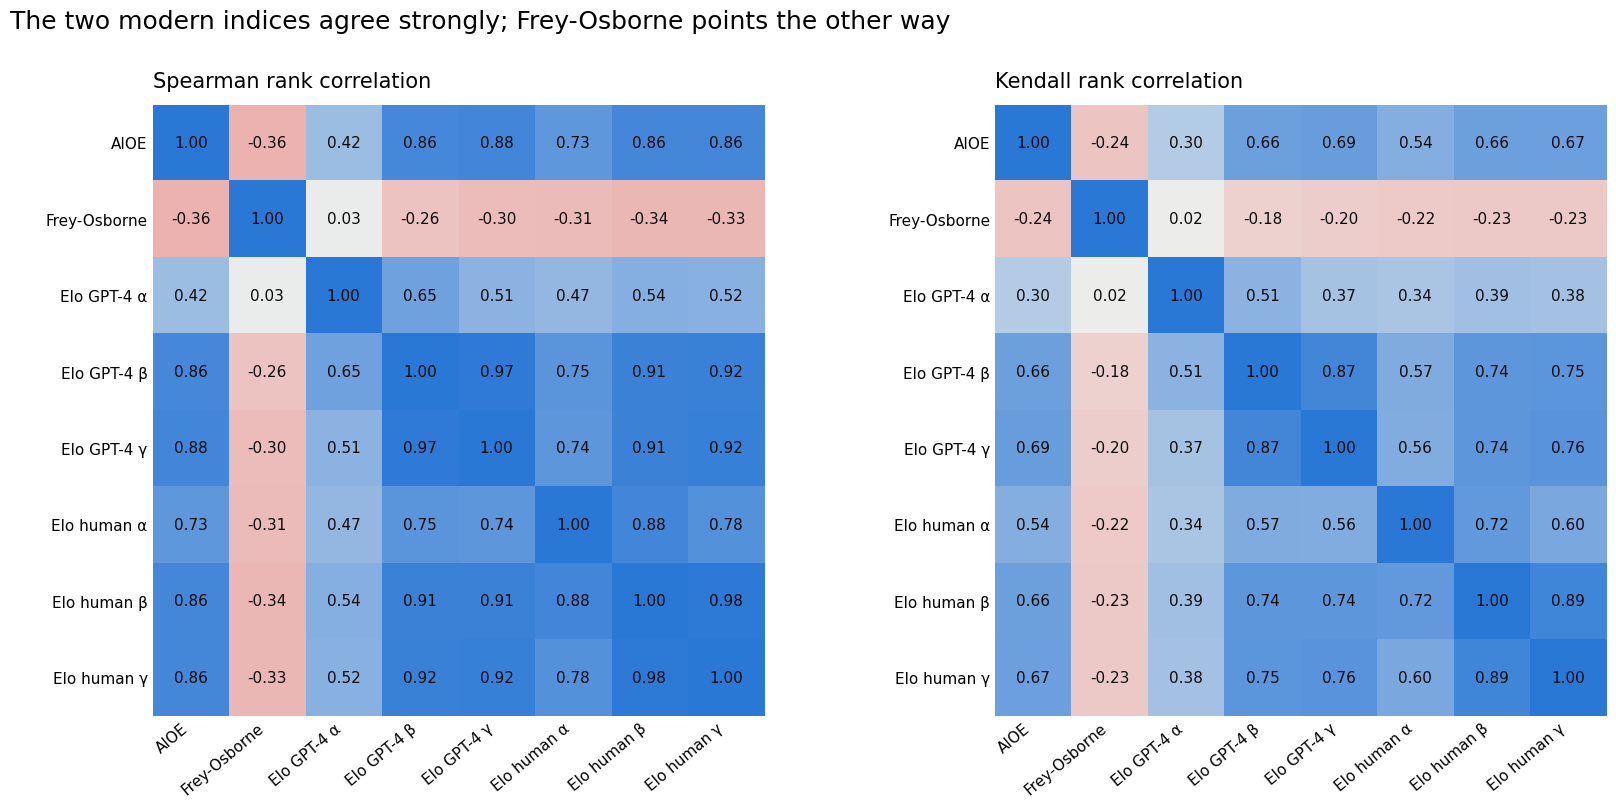

In [ ]:
cmap = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', '#2a78d6'])

fig, axes = plt.subplots(1, 2, figsize=(17, 8.2))
for ax, mat, title in zip(axes, [spearman, kendall], ['Spearman rank correlation', 'Kendall rank correlation']):
    n = len(mat)
    ax.imshow(mat.values, cmap=cmap, vmin=-1, vmax=1)
    for i in range(n):
        for j in range(n):
            v = mat.values[i, j]
            r, g, b = cmap((v + 1) / 2)[:3]
            lum = 0.2126 * r + 0.7152 * g + 0.0722 * b
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=11,
                    color='#0b0b0b' if lum > 0.35 else '#ffffff')
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(mat.columns, rotation=40, ha='right', fontsize=11)
    ax.set_yticklabels(mat.index, fontsize=11)
    ax.set_title(title, fontsize=15, loc='left', pad=12)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
fig.suptitle('The two modern indices agree strongly; Frey-Osborne points the other way', fontsize=18, x=0.02, ha='left')
plt.tight_layout(rect=[0, 0.02, 1, 0.95])
fig.savefig(f'{FIGURES}/rank_correlation_heatmaps.png', dpi=130, bbox_inches='tight')
plt.show()

In [ ]:
changed = df[['aioe_is_split', 'aioe_is_merge', 'fo_is_split', 'fo_is_merge']].any(axis=1)
clean = df[~changed]
print(f'{changed.sum()} occupations touched by a split or merge; {len(clean)} remain')

spearman_clean = clean[COLS].corr(method='spearman').rename(index=LABELS, columns=LABELS).round(3)
print('Largest change in any Spearman correlation:', round((spearman_clean - spearman).abs().max().max(), 3))
spearman_clean.to_csv(f'{PROCESSED}/spearman_matrix_no_split_merge.csv')

58 occupations touched by a split or merge; 635 remain
Largest change in any Spearman correlation: 0.018


In [ ]:
ranks = pd.DataFrame({
    'soc': df['soc'],
    'title': df['title'],
    'aioe': df['AIOE'].rank(pct=True),
    'fo': df['probability'].rank(pct=True),
    'elo_gpt4': df['dv_rating_beta'].rank(pct=True),
    'elo_human': df['human_rating_beta'].rank(pct=True),
}).round(4)
ranks.to_csv(f'{PROCESSED}/percentile_ranks.csv', index=False)
ranks.head()

,soc,title,aioe,fo,elo_gpt4,elo_human
0,11-1011,Chief Executives,0.9206,0.0974,0.7980,0.6566
1,11-1021,General and Operations Managers,0.6609,0.2814,0.7388,0.6732
2,11-2011,Advertising and Promotions Managers,0.8990,0.1797,0.7330,0.8918
3,11-2021,Marketing Managers,0.9091,0.0873,0.7799,0.9163
4,11-2022,Sales Managers,0.8745,0.0815,0.6970,0.8023


In [ ]:
n = len(ranks)
rows = []
for col, label in [('elo_gpt4', 'GPT-4 labels'), ('elo_human', 'Human labels')]:
    for share in [0.1, 0.2]:
        for top in [True, False]:
            def group(c):
                cut = ranks[c].quantile(1 - share) if top else ranks[c].quantile(share)
                return set(ranks.index[ranks[c] >= cut]) if top else set(ranks.index[ranks[c] <= cut])
            a, e = group('aioe'), group(col)
            rows.append({
                'labels': label,
                'group': ('Most exposed' if top else 'Least exposed') + f' {int(share * 100)}%',
                'aioe_n': len(a), 'elo_n': len(e), 'overlap': len(a & e),
                'overlap_share': round(len(a & e) / len(a), 3),
                'chance_share': round(len(e) / n, 3),
            })
overlap = pd.DataFrame(rows)
overlap.to_csv(f'{PROCESSED}/top_group_overlap.csv', index=False)
overlap

,labels,group,aioe_n,elo_n,overlap,overlap_share,chance_share
0,GPT-4 labels,Most exposed 10%,70,70,15,0.214,0.101
1,GPT-4 labels,Least exposed 10%,70,70,36,0.514,0.101
2,GPT-4 labels,Most exposed 20%,139,139,86,0.619,0.201
3,GPT-4 labels,Least exposed 20%,139,139,96,0.691,0.201
4,Human labels,Most exposed 10%,70,70,23,0.329,0.101
5,Human labels,Least exposed 10%,70,71,38,0.543,0.102
6,Human labels,Most exposed 20%,139,139,85,0.612,0.201
7,Human labels,Least exposed 20%,139,141,94,0.676,0.203


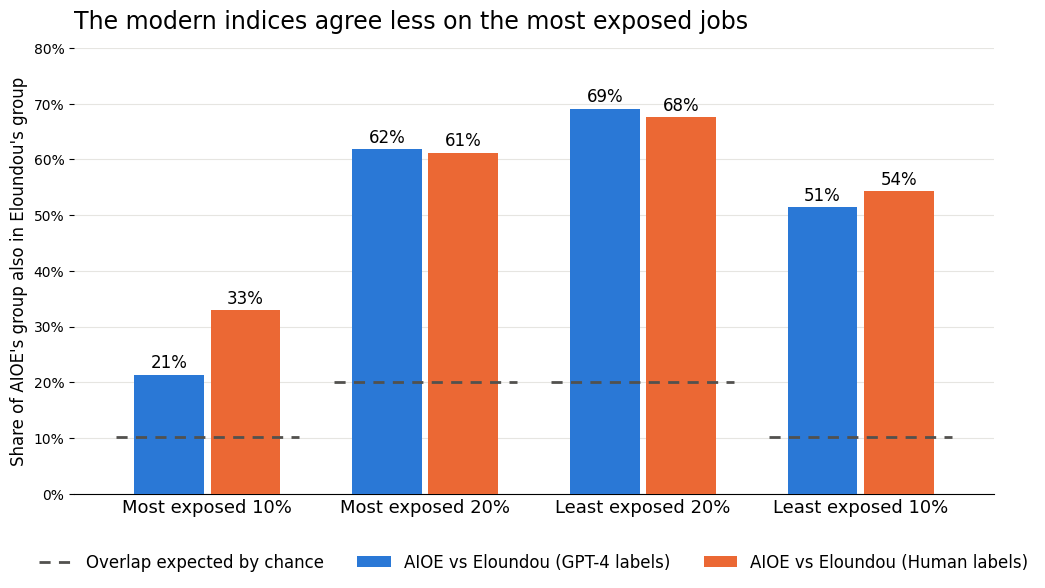

In [ ]:
order = ['Most exposed 10%', 'Most exposed 20%', 'Least exposed 20%', 'Least exposed 10%']
fig, ax = plt.subplots(figsize=(11, 6))
w, x = 0.32, np.arange(4)
for i, (label, color) in enumerate([('GPT-4 labels', '#2a78d6'), ('Human labels', '#eb6834')]):
    d = overlap[overlap['labels'] == label].set_index('group').loc[order]
    bars = ax.bar(x + (i - 0.5) * (w + 0.03), d['overlap_share'] * 100, w, color=color,
                  label=f'AIOE vs Eloundou ({label})', zorder=3)
    for b, v in zip(bars, d['overlap_share'] * 100):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f'{v:.0f}%', ha='center', fontsize=12)
chance = overlap[overlap['labels'] == 'GPT-4 labels'].set_index('group').loc[order]['chance_share'] * 100
for xi, c in zip(x, chance):
    ax.plot([xi - 0.42, xi + 0.42], [c, c], color='#52514e', lw=2, ls=(0, (4, 3)), zorder=4)
ax.plot([], [], color='#52514e', lw=2, ls=(0, (4, 3)), label='Overlap expected by chance')
ax.set_xticks(x); ax.set_xticklabels(order, fontsize=13)
ax.set_ylim(0, 80); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_ylabel("Share of AIOE's group also in Eloundou's group", fontsize=12)
ax.grid(axis='y', color='#e6e5e1', zorder=0)
for s in ['top', 'right', 'left']:
    ax.spines[s].set_visible(False)
ax.tick_params(axis='x', length=0)
ax.legend(frameon=False, fontsize=12, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
ax.set_title('The modern indices agree less on the most exposed jobs', fontsize=17, loc='left', pad=14)
plt.tight_layout()
fig.savefig(f'{FIGURES}/agreement_by_exposure_level.png', dpi=130, bbox_inches='tight')
plt.show()

In [ ]:
r = ranks.copy()
r['modern'] = (r['aioe'] + (r['elo_gpt4'] + r['elo_human']) / 2) / 2
r['modern_minus_fo'] = r['modern'] - r['fo']
r['aioe_minus_elo'] = r['aioe'] - (r['elo_gpt4'] + r['elo_human']) / 2
r['gpt4_minus_human'] = r['elo_gpt4'] - r['elo_human']

parts = [
    ('Modern indices high, Frey-Osborne low', r.nlargest(6, 'modern_minus_fo')),
    ('Modern indices low, Frey-Osborne high', r.nsmallest(6, 'modern_minus_fo')),
    ('AIOE higher than Eloundou', r.nlargest(4, 'aioe_minus_elo')),
    ('Eloundou higher than AIOE', r.nsmallest(4, 'aioe_minus_elo')),
    ('GPT-4 labels higher than human labels', r.nlargest(3, 'gpt4_minus_human')),
    ('Human labels higher than GPT-4 labels', r.nsmallest(3, 'gpt4_minus_human')),
]
cases = pd.concat([d.assign(pattern=p) for p, d in parts])[
    ['pattern', 'soc', 'title', 'aioe', 'elo_gpt4', 'elo_human', 'fo']].round(2)
cases.columns = ['pattern', 'soc', 'title', 'aioe_pct', 'eloundou_gpt4_pct', 'eloundou_human_pct', 'frey_osborne_pct']
cases.to_csv(f'{PROCESSED}/case_study_candidates.csv', index=False)
cases

,pattern,soc,title,aioe_pct,eloundou_gpt4_pct,eloundou_human_pct,frey_osborne_pct
242,"Modern indices high, Frey-Osborne low",29-1031,Dietitians and Nutritionists,0.93,0.86,0.77,0.02
126,"Modern indices high, Frey-Osborne low",19-1042,"Medical Scientists, Except Epidemiologists",0.88,0.81,0.91,0.03
140,"Modern indices high, Frey-Osborne low",19-3034,School Psychologists,0.98,0.61,0.92,0.03
200,"Modern indices high, Frey-Osborne low",25-9031,Instructional Coordinators,0.91,0.75,0.87,0.02
67,"Modern indices high, Frey-Osborne low",15-1211,Computer Systems Analysts,0.85,0.91,0.89,0.05
138,"Modern indices high, Frey-Osborne low",19-3032,Industrial-Organizational Psychologists,0.96,0.75,0.92,0.08
473,"Modern indices low, Frey-Osborne high",47-3014,"Helpers--Painters, Paperhangers, Plasterers, a...",0.00,0.03,0.04,0.85
330,"Modern indices low, Frey-Osborne high",37-3011,Landscaping and Groundskeeping Workers,0.02,0.08,0.10,0.88
449,"Modern indices low, Frey-Osborne high",47-2051,Cement Masons and Concrete Finishers,0.02,0.03,0.04,0.85
620,"Modern indices low, Frey-Osborne high",51-9022,"Grinding and Polishing Workers, Hand",0.14,0.10,0.13,0.93


confidence
contested    567
agreed       126
Name: count, dtype: int64 

reason  Frey-Osborne differs  agreed  newer indices split
tier                                                     
Low                      196      10                   25
Medium                   131      67                   33
High                     142      49                   40 

newer indices agree within 20 pts: 85.9% | Frey-Osborne in the same tier: 21.8%


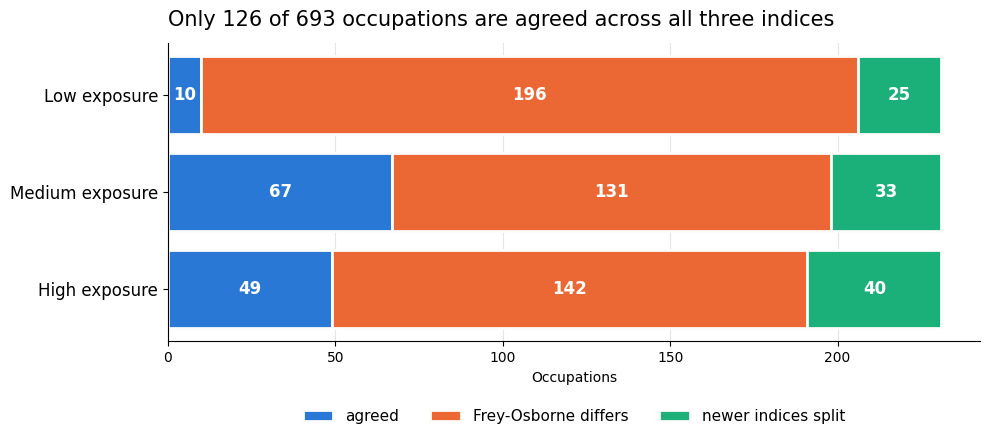

In [ ]:
TIERS = ['Low', 'Medium', 'High']
AGREE_WITHIN = 0.20   # the newer indices "agree" if their percentile ranks are within 20 points

c = ranks.copy()
c['eloundou'] = (c['elo_gpt4'] + c['elo_human']) / 2     # blend of the two Eloundou labellers
c['modern'] = (c['aioe'] + c['eloundou']) / 2            # same blend used in the case-study candidates above
c['gap'] = (c['aioe'] - c['eloundou']).abs()             # disagreement between the two newer indices

# Consensus exposure tier: equal thirds of the newer-index blend
c['tier'] = pd.qcut(c['modern'], 3, labels=TIERS)
# Frey-Osborne's own tier, from its own ranking
c['fo_tier'] = pd.cut(c['fo'], [0, 1/3, 2/3, 1], labels=TIERS, include_lowest=True)

c['newer_indices_agree'] = c['gap'] <= AGREE_WITHIN
c['fo_matches_tier'] = c['fo_tier'].astype(str) == c['tier'].astype(str)

# Confidence flag: agreed only if the newer indices agree AND Frey-Osborne lands in the same tier
c['confidence'] = np.where(c['newer_indices_agree'] & c['fo_matches_tier'], 'agreed', 'contested')
c['reason'] = np.select(
    [c['confidence'] == 'agreed', ~c['newer_indices_agree']],
    ['', 'newer indices split'],
    default='Frey-Osborne differs')

# Extra cautions (do not change the flag)
c['labellers_split'] = (c['elo_gpt4'] - c['elo_human']).abs() > AGREE_WITHIN   # GPT-4 vs human labels far apart
c['crosswalk_touched'] = changed.values                                        # score came from a split/merge code

c.round(3).to_csv(f'{PROCESSED}/consensus_table.csv', index=False)

print(c['confidence'].value_counts(), '\n')
print(pd.crosstab(c['tier'], c['reason'].replace('', 'agreed')), '\n')
print(f"newer indices agree within 20 pts: {c['newer_indices_agree'].mean():.1%} | "
      f"Frey-Osborne in the same tier: {c['fo_matches_tier'].mean():.1%}")

# Chart: how the flag splits inside each tier
counts = pd.crosstab(c['tier'], c['reason'].replace('', 'agreed')).reindex(
    columns=['agreed', 'Frey-Osborne differs', 'newer indices split'])
colors = {'agreed': '#2a78d6', 'Frey-Osborne differs': '#eb6834', 'newer indices split': '#1baf7a'}
fig, ax = plt.subplots(figsize=(10, 4.6))
left = np.zeros(len(counts))
for col in counts.columns:
    ax.barh(range(len(counts)), counts[col], left=left, color=colors[col], edgecolor='#fcfcfb', linewidth=2, label=col)
    for i, v in enumerate(counts[col]):
        if v >= 9:
            ax.text(left[i] + v / 2, i, str(v), ha='center', va='center', color='white', fontsize=12, fontweight='bold')
    left += counts[col].to_numpy()
ax.set_yticks(range(len(counts))); ax.set_yticklabels([f'{t} exposure' for t in counts.index], fontsize=12)
ax.invert_yaxis()
ax.set_xlabel('Occupations')
ax.set_title(f"Only {(c['confidence'] == 'agreed').sum()} of {len(c)} occupations are agreed across all three indices",
             fontsize=15, loc='left', pad=12)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.grid(axis='x', color='#e6e5e1', zorder=0); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=11, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.tight_layout()
fig.savefig(f'{FIGURES}/consensus_flags_by_tier.png', dpi=130, bbox_inches='tight')
plt.show()

,soc,occupation,aioe,elo_gpt4,elo_human,fo,tier,confidence,reason,labellers_split,crosswalk_touched
0,25-2021,Elementary school teachers,74,52,57,3,Medium,contested,Frey-Osborne differs,False,False
1,25-2031,Secondary school teachers,85,54,62,6,High,contested,newer indices split,False,False
2,43-6014,Secretaries & admin. assistants,81,93,90,90,High,agreed,,False,False
3,43-4051,Customer service reps,76,88,98,45,High,contested,Frey-Osborne differs,False,False
4,41-2011,Cashiers,48,39,64,93,Medium,contested,Frey-Osborne differs,True,False
5,41-2031,Retail salespersons,56,56,63,81,Medium,contested,Frey-Osborne differs,False,False
6,15-1252,Software developers,87,98,75,24,High,contested,Frey-Osborne differs,True,True
7,13-2011,Accountants & auditors,99,87,86,85,High,agreed,,False,False
8,53-3032,Heavy truck drivers,14,48,41,61,Low,contested,newer indices split,False,False
9,35-2014,Restaurant cooks,31,22,32,90,Low,contested,Frey-Osborne differs,False,False


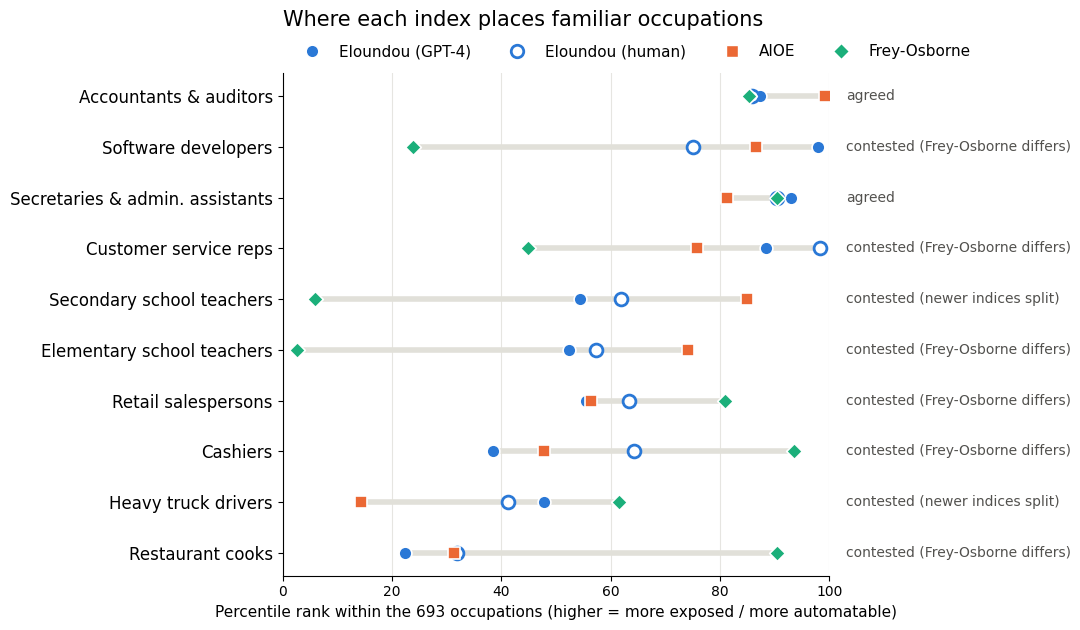

In [ ]:
from matplotlib.lines import Line2D

CASES = {
    '25-2021': 'Elementary school teachers',
    '25-2031': 'Secondary school teachers',
    '43-6014': 'Secretaries & admin. assistants',
    '43-4051': 'Customer service reps',
    '41-2011': 'Cashiers',
    '41-2031': 'Retail salespersons',
    '15-1252': 'Software developers',
    '13-2011': 'Accountants & auditors',
    '53-3032': 'Heavy truck drivers',
    '35-2014': 'Restaurant cooks',
}
missing = set(CASES) - set(c['soc'])
assert not missing, f'not in the merged table: {missing}'

cs = c.set_index('soc').loc[list(CASES)].reset_index()
cs.insert(1, 'occupation', cs['soc'].map(CASES))
PCT = ['aioe', 'elo_gpt4', 'elo_human', 'fo']
table = cs[['soc', 'occupation'] + PCT + ['tier', 'confidence', 'reason', 'labellers_split', 'crosswalk_touched']].copy()
table[PCT] = (table[PCT] * 100).round(0).astype(int)          # show as percentile ranks 0-100
table.to_csv(f'{PROCESSED}/case_studies.csv', index=False)
display(table)

# Dot plot: where each index puts each occupation (sorted by the newer-index blend)
plot = cs.sort_values('modern').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 6.4))
for y, r in plot.iterrows():
    vals = [r[k] * 100 for k in PCT]
    ax.hlines(y, min(vals), max(vals), color='#e1e0d9', lw=4, zorder=1)
    ax.scatter(r['elo_gpt4'] * 100, y, marker='o', s=85, color='#2a78d6', zorder=3, edgecolor='white', linewidth=1.2)
    ax.scatter(r['elo_human'] * 100, y, marker='o', s=85, facecolor='white', edgecolor='#2a78d6', linewidth=2, zorder=3)
    ax.scatter(r['aioe'] * 100, y, marker='s', s=72, color='#eb6834', zorder=3, edgecolor='white', linewidth=1.2)
    ax.scatter(r['fo'] * 100, y, marker='D', s=64, color='#1baf7a', zorder=3, edgecolor='white', linewidth=1.2)
    ax.text(103, y, r['confidence'] + (f" ({r['reason']})" if r['reason'] else ''), va='center', fontsize=10, color='#52514e')
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot['occupation'], fontsize=12)
ax.set_xlim(0, 100)
ax.set_xlabel('Percentile rank within the 693 occupations (higher = more exposed / more automatable)', fontsize=11)
ax.set_title('Where each index places familiar occupations', fontsize=15, loc='left', pad=34)
ax.legend(handles=[
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#2a78d6', markeredgecolor='white', markersize=9, label='Eloundou (GPT-4)'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='white', markeredgecolor='#2a78d6', markeredgewidth=2, markersize=9, label='Eloundou (human)'),
    Line2D([0], [0], marker='s', color='none', markerfacecolor='#eb6834', markeredgecolor='white', markersize=9, label='AIOE'),
    Line2D([0], [0], marker='D', color='none', markerfacecolor='#1baf7a', markeredgecolor='white', markersize=8, label='Frey-Osborne')],
    loc='lower left', bbox_to_anchor=(0, 1.0), ncol=4, frameon=False, fontsize=11)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.grid(axis='x', color='#e6e5e1', zorder=0); ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig(f'{FIGURES}/case_studies.png', dpi=130, bbox_inches='tight')
plt.show()